In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')


In [3]:
df = pd.read_csv("Salary_dataset.csv")

In [4]:
df.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [5]:
df.columns

Index(['Unnamed: 0', 'YearsExperience', 'Salary'], dtype='object')

In [6]:
df.rename(columns={'Unnamed: 0': 'Employee_Id'}, inplace=True)

In [7]:
df.columns

Index(['Employee_Id', 'YearsExperience', 'Salary'], dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Employee_Id      30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes


In [9]:
df.shape

(30, 3)

In [10]:
df.isnull().sum()

Employee_Id        0
YearsExperience    0
Salary             0
dtype: int64

In [16]:
df = df.drop("Employee_Id", axis=1)

In [28]:
df[df.duplicated()]

,YearsExperience,Salary


In [17]:
df.columns

Index(['YearsExperience', 'Salary'], dtype='object')

(array([4., 2., 5., 4., 3., 2., 2., 2., 3., 3.]),
 array([ 1.2 ,  2.14,  3.08,  4.02,  4.96,  5.9 ,  6.84,  7.78,  8.72,
         9.66, 10.6 ]),
 <BarContainer object of 10 artists>)

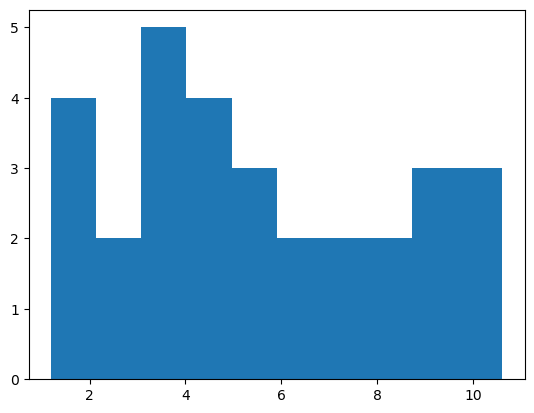

In [18]:
plt.hist(df["YearsExperience"])

(array([4., 2., 7., 4., 0., 2., 2., 2., 4., 3.]),
 array([ 37732.,  46198.,  54664.,  63130.,  71596.,  80062.,  88528.,
         96994., 105460., 113926., 122392.]),
 <BarContainer object of 10 artists>)

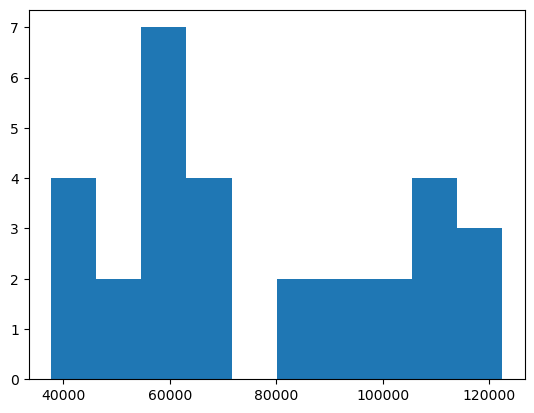

In [19]:
plt.hist(df["Salary"])

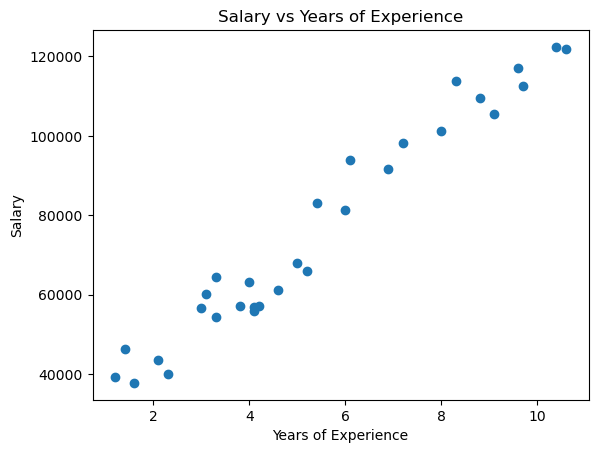

In [21]:
plt.scatter(df["YearsExperience"], df["Salary"])
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary vs Years of Experience")
plt.show()

<Axes: >

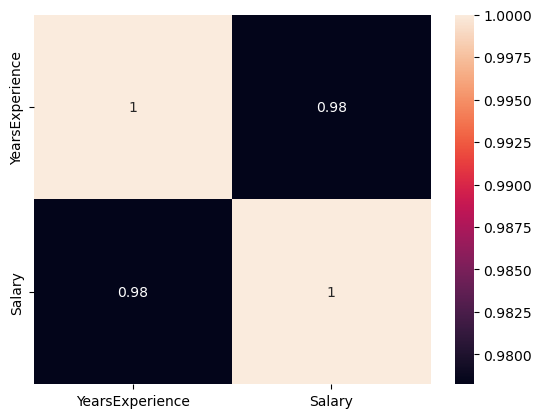

In [23]:
sns.heatmap(df.corr(numeric_only = True), annot=True)

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27],
 [Text(0, 0, '1.2000000000000002'),
  Text(1, 0, '1.4'),
  Text(2, 0, '1.6'),
  Text(3, 0, '2.1'),
  Text(4, 0, '2.3000000000000003'),
  Text(5, 0, '3.0'),
  Text(6, 0, '3.1'),
  Text(7, 0, '3.3000000000000003'),
  Text(8, 0, '3.8'),
  Text(9, 0, '4.0'),
  Text(10, 0, '4.1'),
  Text(11, 0, '4.199999999999999'),
  Text(12, 0, '4.6'),
  Text(13, 0, '5.0'),
  Text(14, 0, '5.199999999999999'),
  Text(15, 0, '5.4'),
  Text(16, 0, '6.0'),
  Text(17, 0, '6.1'),
  Text(18, 0, '6.9'),
  Text(19, 0, '7.199999999999999'),
  Text(20, 0, '8.0'),
  Text(21, 0, '8.299999999999999'),
  Text(22, 0, '8.799999999999999'),
  Text(23, 0, '9.1'),
  Text(24, 0, '9.6'),
  Text(25, 0, '9.7'),
  Text(26, 0, '10.4'),
  Text(27, 0, '10.6')])

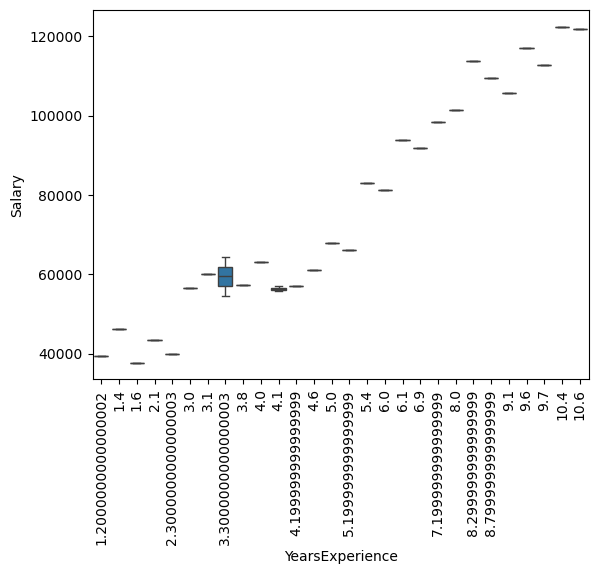

In [26]:
sns.boxplot(x=df["YearsExperience"], y=df["Salary"])
plt.xticks(rotation=90)

In [29]:
df.head()

,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [31]:
x = df[["YearsExperience"]]
y = df[["Salary"]]


In [33]:
X_train, X_test, Y_train, Y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [34]:
model = LinearRegression()
model.fit(X_train, Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [35]:
y_pred = model.predict(X_test)

In [36]:
y_pred

array([[115791.21011287],
       [ 71499.27809463],
       [102597.86866063],
       [ 75268.80422384],
       [ 55478.79204548],
       [ 60190.69970699]])

In [38]:
Y_test

,Salary
27,112636.0
15,67939.0
23,113813.0
17,83089.0
8,64446.0
9,57190.0


In [40]:
r2 = r2_score(Y_test, y_pred)
r2

0.9024461774180498

In [41]:
n = X_test.shape[0]
p = X_test.shape[1]

adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
adjusted_r2

0.8780577217725622